<a href="https://colab.research.google.com/github/recxdivist/ocean_lab/blob/main/Lab01_oxygen.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import kagglehub
path = kagglehub.dataset_download("sohier/calcofi")
print(path)

import os
print(os.listdir(path))

100%|██████████| 50.4M/50.4M [00:00<00:00, 94.2MB/s]

Extracting files...


/root/.cache/kagglehub/datasets/sohier/calcofi/versions/2
['cast.csv', 'bottle.csv']


In [ ]:
import pandas as pd

df = pd.read_csv(path + "/bottle.csv", encoding="latin-1", low_memory=False)
print("Строк и столбцов:", df.shape)

oxygen = df["O2ml_L"]
print("Пропусков в кислороде:", oxygen.isna().sum())
print(oxygen.head(10))


Строк и столбцов: (864863, 74)
Пропусков в кислороде: 168662
0   NaN
1   NaN
2   NaN
3   NaN
4   NaN
5   NaN
6   NaN
7   NaN
8   NaN
9   NaN
Name: O2ml_L, dtype: float64


In [ ]:
oxygen = oxygen.dropna()
print("Осталось значений:", len(oxygen))
print(oxygen.describe())

Осталось значений: 696201
count    696201.000000
mean          3.392468
std           2.073256
min          -0.010000
25%           1.360000
50%           3.440000
75%           5.500000
max          11.130000
Name: O2ml_L, dtype: float64


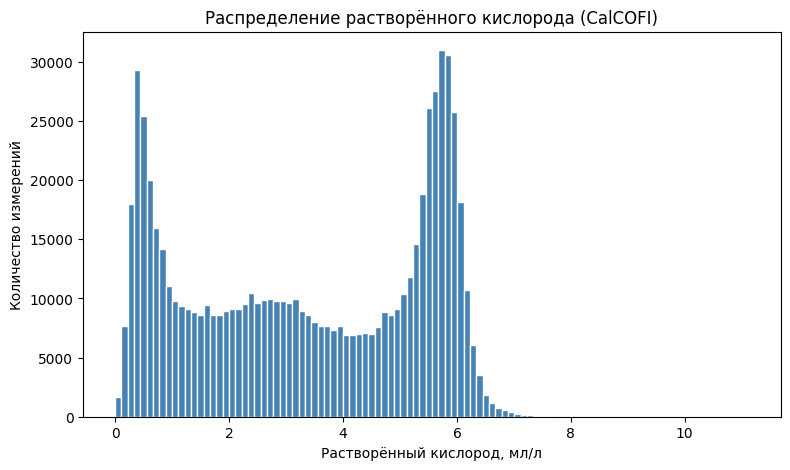

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
plt.hist(oxygen, bins=100, color="steelblue", edgecolor="white")
plt.xlabel("Растворённый кислород, мл/л")
plt.ylabel("Количество измерений")
plt.title("Распределение растворённого кислорода (CalCOFI)")
plt.show()


In [ ]:
o2_100 = df.loc[df["Depthm"] == 100, "O2ml_L"].dropna()
print("Число измерений на глубине 100 м:", len(o2_100))
print(o2_100.describe())

Число измерений на глубине 100 м: 22096
count    22096.000000
mean         4.135426
std          1.228856
min          0.060000
25%          3.230000
50%          4.150000
75%          5.260000
max          6.930000
Name: O2ml_L, dtype: float64


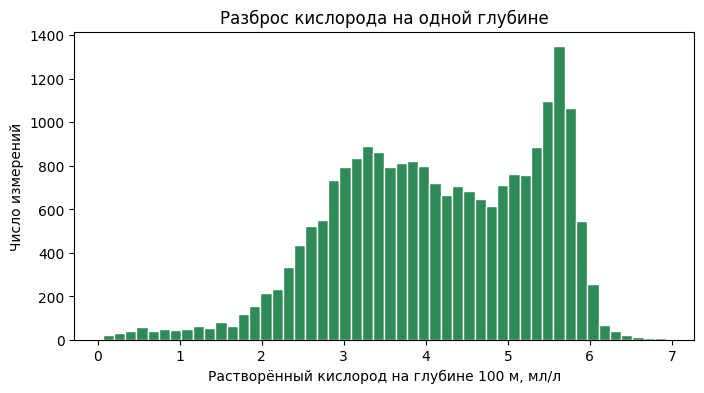

In [ ]:
plt.figure(figsize=(8, 4))
plt.hist(o2_100, bins=50, color="seagreen", edgecolor="white")
plt.xlabel("Растворённый кислород на глубине 100 м, мл/л")
plt.ylabel("Число измерений")
plt.title("Разброс кислорода на одной глубине")
plt.show()


Мы взяли измерения на одной глубине (100 м). Всего таких измерений оказалось 22096. Минимальное значение - 0,06 мл/л, максимальное - 6,93 мл/л. Среднее значение - 4,14 мл/л, std = 1,23 мл/л. Половина значений находится между 3,23 и 5,26 мл/л.
Если бы кислород был функцией, зависящей только от глубины, все значения на одной глубине были бы одинаковыми, минимум был бы равен максимуму, разброс (std) был бы равен 0, а на гистограмме был бы только один столбик. На деле значения растворённого кислорода на одной глубине сильно различаются (от 0,06 до 6,93 мл/л), std = 1,23 мл/л, то есть отличен от нуля, а гистограмма состоит из множества столбиков. Значит, растворённый кислород не определяется одной лишь глубиной.
Разброс объясняется тем, что кислород зависит не только от глубины, но и от времени года, когда бралась проба, от места станции и года измерения, от состояния океана (течения, подъём глубинных вод), от количества планктона, который поглощает и выделяет кислород.
Таким образом, мы сделали вывод, что кислород - это случайная величина: его значение в отдельном измерении нельзя заранее точно предсказать, даже зная глубину.